# 09 · Classical ML vs transformer: comparison
**Owner:** Kasula Lalithendra

Phase 2. Every method is tested on the three test sets from notebook 06 (original, paraphrasing,
refactorization):

| Method | Reads the claim with | Causal reasoning |
|---|---|---|
| Phase 1 pipeline | regex | PC graph |
| Classical ML reader | TF-IDF + Logistic Regression (notebook 07) | PC graph |
| Transformer reader | DistilBERT (notebook 07) | PC graph |
| End-to-end transformer | DistilBERT reads everything (notebook 08) | none |

With a graph, a claim is called valid when it is true in every DAG that fits the premise (`mec_support` = 1), the
no-learning rule from Phase 1. In Phase 1 the Random Forest beat this rule by only 0.005 F1, inside the confidence
interval, so here the rule is enough and the comparison is only about **reading**.

In [1]:
# ─── IMPORTS ─────
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

sys.path.insert(0, "../src")
from c2c.graphs import find_graph, all_dags, mec_support
from c2c.parsing import parse_hypothesis

warnings.filterwarnings("ignore")

In [2]:
# ─── LOAD DATA ─────
test_sets = pd.read_csv("../data/processed/test_sets.csv")
readers = pd.read_csv("../data/processed/reader_predictions.csv")
e2e = pd.read_csv("../data/processed/e2e_predictions.csv")

data = test_sets.merge(readers.drop(columns="test_set"), on="row_id").merge(e2e.drop(columns="test_set"), on="row_id")
print(test_sets.shape, data.shape)
data[["test_set", "hypothesis", "label", "relation_regex", "relation_tfidf", "relation_bert", "e2e_proba"]].head()

(5654, 10) (5654, 19)


,test_set,hypothesis,label,relation_regex,relation_tfidf,relation_bert,e2e_proba
0,original,"There exists at least one collider (i.e., comm...",0,collider,collider,collider,0.914185
1,original,A directly causes B.,0,direct_cause,direct_cause,direct_cause,0.001412
2,original,"A is a cause for B, but not a direct one.",0,indirect_cause,indirect_cause,indirect_cause,0.001371
3,original,B directly causes A.,0,direct_cause,direct_cause,direct_cause,0.001508
4,original,B causes something else which causes A.,0,indirect_cause,indirect_cause,indirect_cause,0.001366


In [3]:
# ─── STEP 1: GRAPHS FOR THE 21 TEST PREMISES ─────
# after renaming, all three test sets share the same 21 premises, so we run PC once per premise (as in notebook 02)
premises = data.drop_duplicates("premise_id")

dags_of = {}
for premise_id, premise in zip(premises["premise_id"], premises["premise"]):
    dags_of[premise_id] = all_dags(find_graph(premise))

# number of fitting DAGs for each premise
for premise_id in dags_of:
    print(premise_id, len(dags_of[premise_id]))

2358 2
2359 1
2360 3
2341 6
2361 6
2362 10
2363 32
2364 3
2365 2
2366 5
2346 1
2367 1
2368 1
2369 6
2370 13
2356 4
2371 2
2372 6
2373 1
2374 4
2375 2


In [4]:
# ─── STEP 2: CHECK EVERY CLAIM WITH EACH READER ─────
# mec_support = share of fitting DAGs where the claim is true; a claim the reader could not read gets 0
def support(row, reader):
    if row[reader] == "unknown":
        return 0.0
    return mec_support(dags_of[row["premise_id"]], row[reader], row["x"], row["y"])


data["support_regex"] = data.apply(lambda r: support(r, "relation_regex"), axis=1)
data["support_tfidf"] = data.apply(lambda r: support(r, "relation_tfidf"), axis=1)
data["support_bert"] = data.apply(lambda r: support(r, "relation_bert"), axis=1)

data["pred_regex"] = (data["support_regex"] == 1).astype(int)
data["pred_tfidf"] = (data["support_tfidf"] == 1).astype(int)
data["pred_bert"] = (data["support_bert"] == 1).astype(int)

In [5]:
# ─── STEP 3: F1 ON THE THREE TEST SETS ─────
original = data[data["test_set"] == "original"]
paraphrasing = data[data["test_set"] == "paraphrasing"]
refactorization = data[data["test_set"] == "refactorization"]

results = pd.DataFrame({
    "original": [f1_score(original["label"], original["pred_regex"]), f1_score(original["label"], original["pred_tfidf"]),
                 f1_score(original["label"], original["pred_bert"]), f1_score(original["label"], original["e2e_pred"])],
    "paraphrasing": [f1_score(paraphrasing["label"], paraphrasing["pred_regex"]), f1_score(paraphrasing["label"], paraphrasing["pred_tfidf"]),
                     f1_score(paraphrasing["label"], paraphrasing["pred_bert"]), f1_score(paraphrasing["label"], paraphrasing["e2e_pred"])],
    "refactorization": [f1_score(refactorization["label"], refactorization["pred_regex"]), f1_score(refactorization["label"], refactorization["pred_tfidf"]),
                        f1_score(refactorization["label"], refactorization["pred_bert"]), f1_score(refactorization["label"], refactorization["e2e_pred"])],
}, index=["regex + PC (Phase 1)", "TF-IDF reader + PC", "DistilBERT reader + PC", "End-to-end DistilBERT"])
results.round(3)

,original,paraphrasing,refactorization
regex + PC (Phase 1),0.952,0.000,0.948
TF-IDF reader + PC,0.952,0.536,0.948
DistilBERT reader + PC,0.952,0.948,0.948
End-to-end DistilBERT,0.528,0.388,0.294


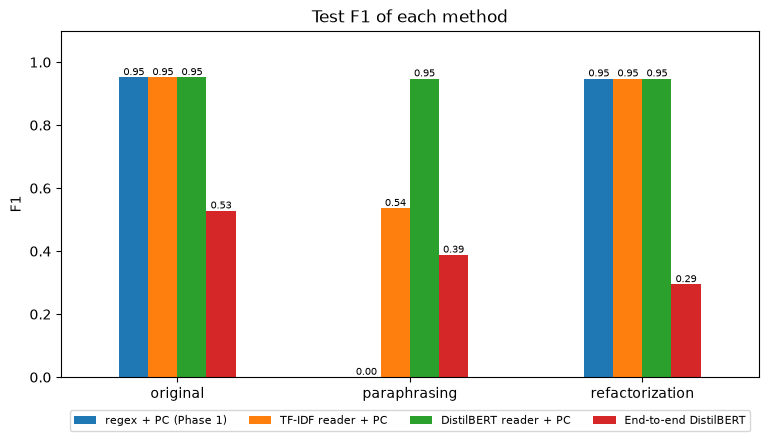

In [6]:
ax = results.T.plot(kind="bar", figsize=(9, 4.5), ylim=(0, 1.1), title="Test F1 of each method")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=7)   # print the value on every bar (so a 0 still shows)
plt.xticks(rotation=0)
plt.xlabel("")
plt.ylabel("F1")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=8)
plt.savefig("../report/figures/comparison_f1.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# precision and recall of the two DistilBERT methods
pd.DataFrame({
    "DistilBERT reader + PC: precision": [precision_score(original["label"], original["pred_bert"]),
                                          precision_score(paraphrasing["label"], paraphrasing["pred_bert"]),
                                          precision_score(refactorization["label"], refactorization["pred_bert"])],
    "DistilBERT reader + PC: recall": [recall_score(original["label"], original["pred_bert"]),
                                       recall_score(paraphrasing["label"], paraphrasing["pred_bert"]),
                                       recall_score(refactorization["label"], refactorization["pred_bert"])],
    "End-to-end: precision": [precision_score(original["label"], original["e2e_pred"]),
                              precision_score(paraphrasing["label"], paraphrasing["e2e_pred"]),
                              precision_score(refactorization["label"], refactorization["e2e_pred"])],
    "End-to-end: recall": [recall_score(original["label"], original["e2e_pred"]),
                           recall_score(paraphrasing["label"], paraphrasing["e2e_pred"]),
                           recall_score(refactorization["label"], refactorization["e2e_pred"])],
}, index=["original", "paraphrasing", "refactorization"]).round(3)

,DistilBERT reader + PC: precision,DistilBERT reader + PC: recall,End-to-end: precision,End-to-end: recall
original,0.922,0.983,0.367,0.939
paraphrasing,0.920,0.977,0.301,0.547
refactorization,0.920,0.977,0.204,0.529


* On the **original** wording every reader works, so all three graph pipelines score 0.952, the same as the
  Phase 1 rule.
* On **paraphrasing** the regex reads nothing (F1 = 0) and the TF-IDF reader swaps colliders and confounders
  (0.536). DistilBERT reads the new wordings and keeps 0.948.
* The **end-to-end** model never builds a graph and has to learn the causal rules from text alone: 0.528 on the
  original test, 0.388 reworded and 0.294 renamed.

In [8]:
# ─── STEP 4: WHAT RENAMING THE VARIABLES DOES (REFACTORIZATION) ─────
# Phase 1 regex pipeline on the raw text (Z, Y, X, ...): the regex only knows A-F, so it finds no independences
raw = pd.DataFrame({"premise": refactorization["premise_raw"], "hypothesis": refactorization["hypothesis_raw"],
                    "label": refactorization["label"]})
raw = parse_hypothesis(raw)   # x, y and relation from the raw claim

# PC on every raw premise
raw_dags = {}
for premise in raw["premise"].unique():
    raw_dags[premise] = all_dags(find_graph(premise))

raw["support"] = raw.apply(lambda r: mec_support(raw_dags[r["premise"]], r["relation"], r["x"], r["y"]), axis=1)
raw["pred"] = (raw["support"] == 1).astype(int)

In [9]:
e2e_renamed_pred = (refactorization["e2e_proba_renamed"] >= 0.5).astype(int)

print("regex + PC,  raw names:     ", round(f1_score(raw["label"], raw["pred"]), 3))
print("regex + PC,  renamed to A-F:", round(f1_score(refactorization["label"], refactorization["pred_regex"]), 3))
print("end-to-end,  raw names:     ", round(f1_score(refactorization["label"], refactorization["e2e_pred"]), 3))
print("end-to-end,  renamed to A-F:", round(f1_score(refactorization["label"], e2e_renamed_pred), 3))

regex + PC,  raw names:      0.0
regex + PC,  renamed to A-F: 0.948
end-to-end,  raw names:      0.294
end-to-end,  renamed to A-F: 0.507


The Phase 1 regex only allows the letters A–F, so on the raw renamed text it misses every independence and PC
returns the wrong graph. Our entity schema (rename by position, notebook 06) fixes this with one fixed rule.

In [14]:
# ─── STEP 5: SAVE PREDICTIONS FOR NOTEBOOK 10 ─────
data[["row_id", "test_set", "premise_id", "hypothesis", "x", "y", "label", "relation_true",
      "relation_regex", "relation_bert", "bert_confidence", "pred_regex", "pred_tfidf", "pred_bert", "e2e_pred"]].to_csv(
    "../data/processed/pipeline_predictions.csv", index=False)